**Step 4: Trend Analysis and COVID-19 Impact**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Create a folder for Step 4 figures
figures_dir = Path("figures/step4_trend_covid")
figures_dir.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load dataset
# Load the cleaned dataset from Step 2
df = pd.read_csv("unemployment_cleaned.csv")

# Display the first five rows
display(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names
print("\nColumns:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

,region,date,frequency,estimated_unemployment_rate_(%),estimated_employed,estimated_labour_participation_rate_(%),area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-05-31,Monthly,6.09,4788661.0,37.45,Urban
2,Andhra Pradesh,2019-06-30,Monthly,3.80,4824630.0,36.76,Urban
3,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
4,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural


Dataset shape: (740, 7)

Columns:
['region', 'date', 'frequency', 'estimated_unemployment_rate_(%)', 'estimated_employed', 'estimated_labour_participation_rate_(%)', 'area']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 740 entries, 0 to 739
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   region                                   740 non-null    object 
 1   date                                     740 non-null    object 
 2   frequency                                740 non-null    object 
 3   estimated_unemployment_rate_(%)          740 non-null    float64
 4   estimated_employed                       740 non-null    float64
 5   estimated_labour_participation_rate_(%)  740 non-null    float64
 6   area                                     740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 40.6+ KB

Missing values:


In [3]:
# Inspect the dataset
# Display dataset information
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

display(df.head())

Dataset shape: (740, 7)

Column names:
['region', 'date', 'frequency', 'estimated_unemployment_rate_(%)', 'estimated_employed', 'estimated_labour_participation_rate_(%)', 'area']

Data types:
region                                      object
date                                        object
frequency                                   object
estimated_unemployment_rate_(%)            float64
estimated_employed                         float64
estimated_labour_participation_rate_(%)    float64
area                                        object
dtype: object


,region,date,frequency,estimated_unemployment_rate_(%),estimated_employed,estimated_labour_participation_rate_(%),area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-05-31,Monthly,6.09,4788661.0,37.45,Urban
2,Andhra Pradesh,2019-06-30,Monthly,3.80,4824630.0,36.76,Urban
3,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
4,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural


In [4]:
# To prepare the date column
# Replace 'date' with your actual date column name
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Remove rows with invalid dates
df = df.dropna(subset=["date"]).copy()

# Sort observations chronologically
df = df.sort_values("date").reset_index(drop=True)

print("Date range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())

display(df.head())

Date range:
Start: 2019-05-31 00:00:00
End: 2020-06-30 00:00:00


,region,date,frequency,estimated_unemployment_rate_(%),estimated_employed,estimated_labour_participation_rate_(%),area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Odisha,2019-05-31,Monthly,4.17,11155753.0,40.47,Rural
2,Odisha,2019-05-31,Monthly,2.95,2519582.0,41.26,Urban
3,Puducherry,2019-05-31,Monthly,0.00,172474.0,43.08,Rural
4,Puducherry,2019-05-31,Monthly,1.25,283905.0,35.71,Urban


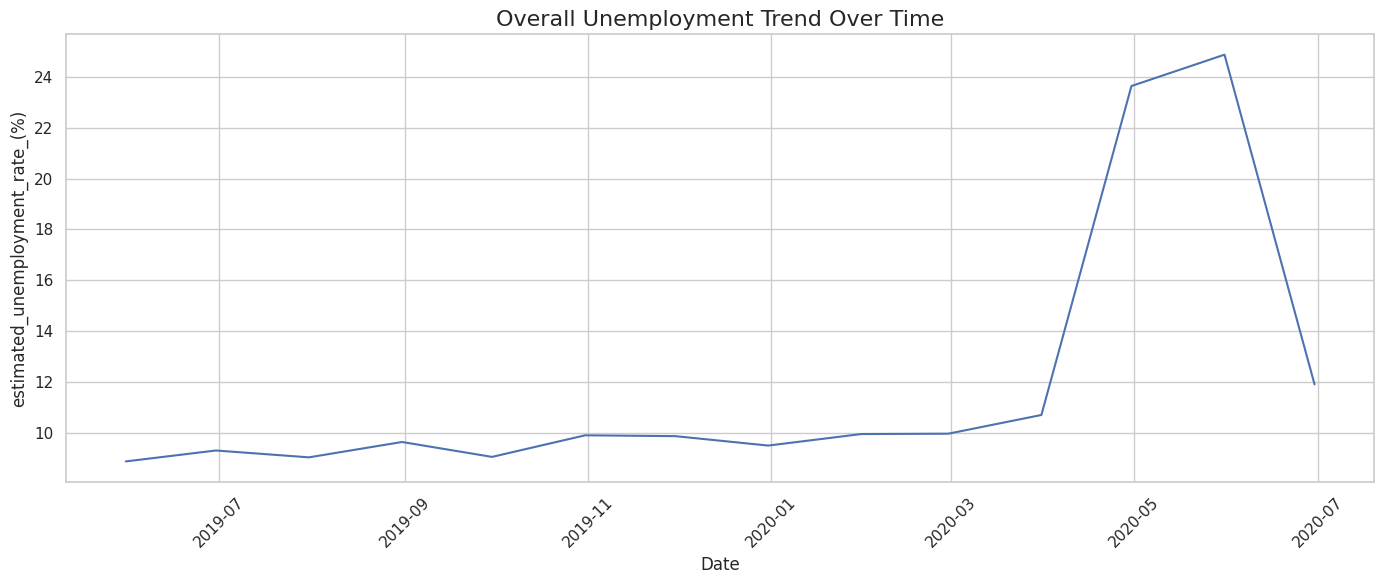

In [5]:
# overall unemployment trend
# Replace with the correct target column
target = "estimated_unemployment_rate_(%)"

# Ensure unemployment values are numeric
df[target] = pd.to_numeric(df[target], errors="coerce")

# Remove missing target values for this analysis
trend_df = df.dropna(subset=[target]).copy()

# Plot the overall trend
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=trend_df,
    x="date",
    y=target,
    errorbar=None
)

plt.title("Overall Unemployment Trend Over Time", fontsize=16)
plt.xlabel("Date")
plt.ylabel("estimated_unemployment_rate_(%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    figures_dir / "01_overall_unemployment_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
# COVID-19 period categories
# Extract year
trend_df["year"] = trend_df["date"].dt.year

# Categorize observations by period
def classify_period(year):
    if 2017 <= year <= 2019:
        return "Pre-COVID"
    elif 2020 <= year <= 2021:
        return "COVID Period"
    elif 2022 <= year <= 2023:
        return "Recovery Period"
    else:
        return "Outside Selected Periods"

trend_df["covid_period"] = trend_df["year"].apply(classify_period)

display(trend_df[["date", target, "year", "covid_period"]].head())

,date,estimated_unemployment_rate_(%),year,covid_period
0,2019-05-31,3.65,2019,Pre-COVID
1,2019-05-31,4.17,2019,Pre-COVID
2,2019-05-31,2.95,2019,Pre-COVID
3,2019-05-31,0.00,2019,Pre-COVID
4,2019-05-31,1.25,2019,Pre-COVID


In [7]:
# Calculate the average unemployment rate for each period
period_order = [
    "Pre-COVID",
    "COVID Period",
    "Recovery Period"
]

period_summary = (
    trend_df[trend_df["covid_period"].isin(period_order)]
    .groupby("covid_period")[target]
    .agg(["mean", "median", "min", "max", "count"])
    .reindex(period_order)
)

period_summary.columns = [
    "Average Rate",
    "Median Rate",
    "Minimum Rate",
    "Maximum Rate",
    "Observations"
]

display(period_summary.round(2))

,Average Rate,Median Rate,Minimum Rate,Maximum Rate,Observations
covid_period,,,,,
Pre-COVID,9.4,7.12,0.0,34.69,430.0
COVID Period,15.1,10.79,0.0,76.74,310.0
Recovery Period,NaN,NaN,NaN,NaN,NaN


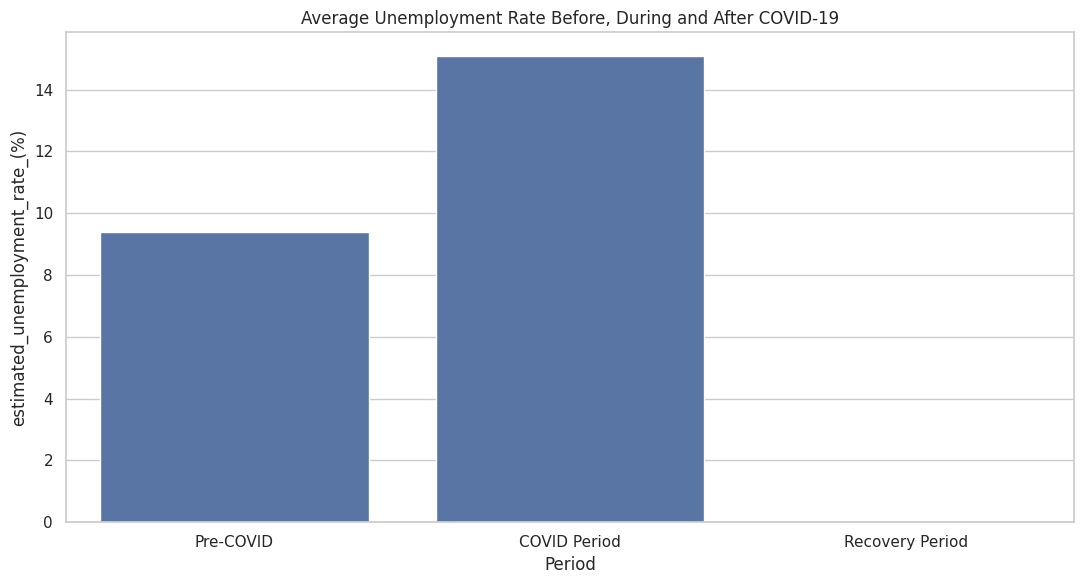

In [8]:
# Comparison
plot_df = trend_df[
    trend_df["covid_period"].isin(period_order)
].copy()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_df,
    x="covid_period",
    y=target,
    order=period_order,
    estimator="mean",
    errorbar=None
)

plt.title("Average Unemployment Rate Before, During and After COVID-19")
plt.xlabel("Period")
plt.ylabel("estimated_unemployment_rate_(%)")
plt.tight_layout()

plt.savefig(
    figures_dir / "02_covid_period_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
# Calculate the percentage-point change
pre_covid = period_summary.loc["Pre-COVID", "Average Rate"]
covid = period_summary.loc["COVID Period", "Average Rate"]
recovery = period_summary.loc["Recovery Period", "Average Rate"]

covid_change = covid - pre_covid
recovery_change = recovery - pre_covid

print(f"Pre-COVID average: {pre_covid:.2f}%")
print(f"COVID-period average: {covid:.2f}%")
print(f"Recovery-period average: {recovery:.2f}%")

print(
    f"\nCOVID vs pre-COVID: "
    f"{covid_change:+.2f} percentage points"
)

print(
    f"Recovery vs pre-COVID: "
    f"{recovery_change:+.2f} percentage points"
)

Pre-COVID average: 9.40%
COVID-period average: 15.10%
Recovery-period average: nan%

COVID vs pre-COVID: +5.70 percentage points
Recovery vs pre-COVID: +nan percentage points


In [10]:
# Highest and lowest unemployed year
annual_summary = (
    trend_df.groupby("year")[target]
    .mean()
    .reset_index(name="average_unemployment")
)

highest_year = annual_summary.loc[
    annual_summary["average_unemployment"].idxmax()
]

lowest_year = annual_summary.loc[
    annual_summary["average_unemployment"].idxmin()
]

print(
    f"Highest annual average: {highest_year['average_unemployment']:.2f}% "
    f"in {int(highest_year['year'])}"
)

print(
    f"Lowest annual average: {lowest_year['average_unemployment']:.2f}% "
    f"in {int(lowest_year['year'])}"
)

Highest annual average: 15.10% in 2020
Lowest annual average: 9.40% in 2019


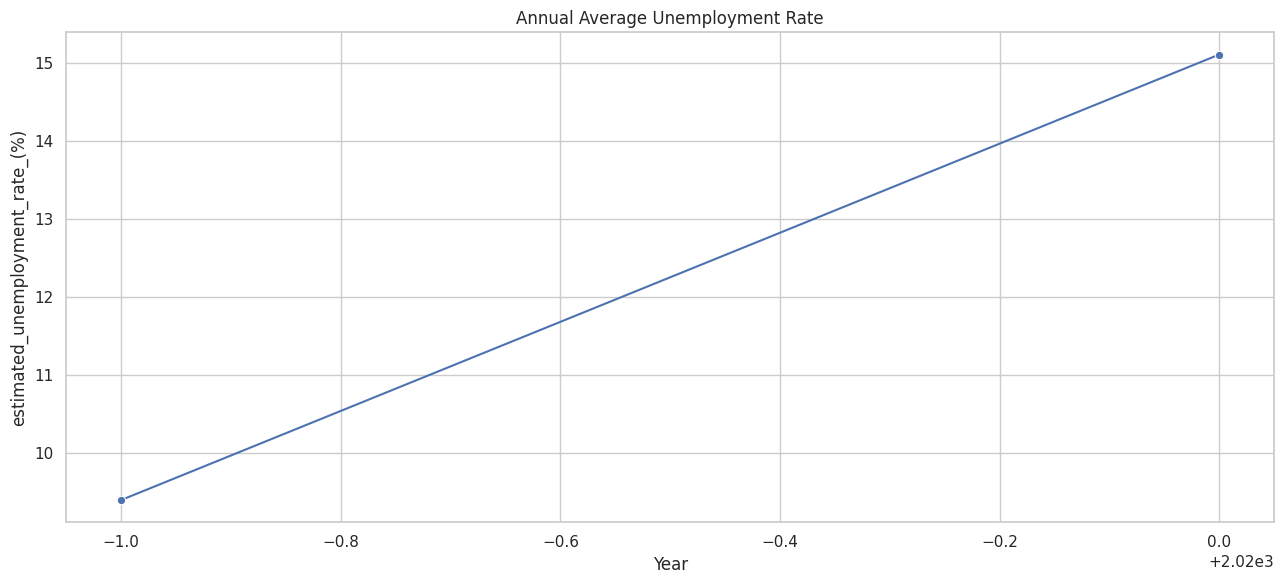

In [11]:
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=annual_summary,
    x="year",
    y="average_unemployment",
    marker="o"
)

plt.title("Annual Average Unemployment Rate")
plt.xlabel("Year")
plt.ylabel("estimated_unemployment_rate_(%)")
plt.tight_layout()

plt.savefig(
    figures_dir / "03_annual_unemployment_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

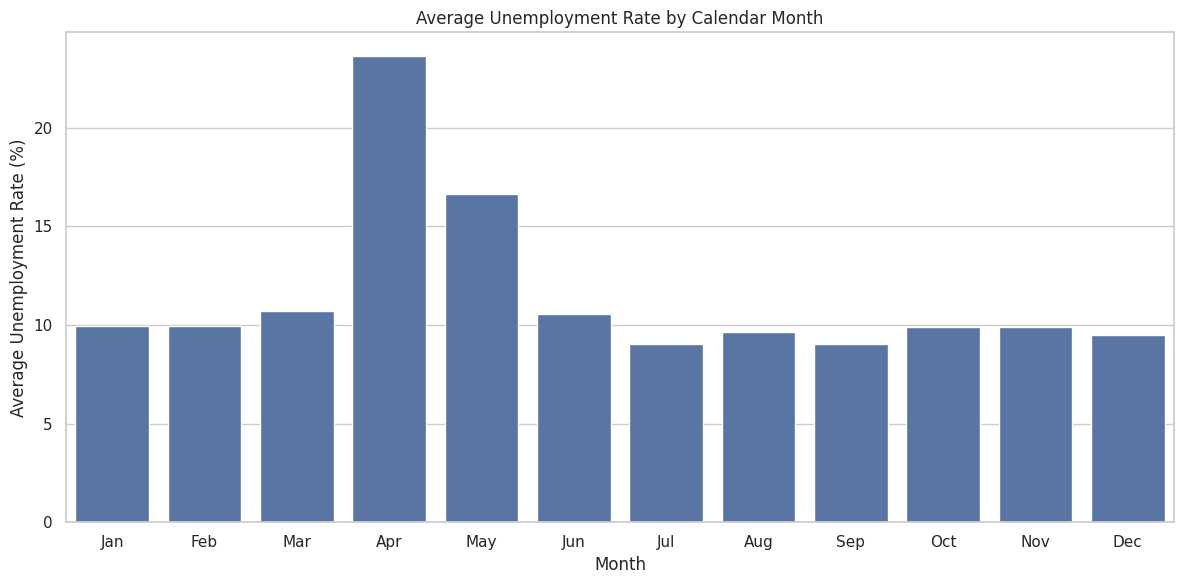

In [12]:
# Monthly Pattern
trend_df["month"] = trend_df["date"].dt.month

monthly_summary = (
    trend_df.groupby("month")[target]
    .mean()
    .reindex(range(1, 13))
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 6))

sns.barplot(
    x=month_names,
    y=monthly_summary.values,
    errorbar=None
)

plt.title("Average Unemployment Rate by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()

plt.savefig(
    figures_dir / "04_monthly_unemployment_pattern.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# Save the analysis results
annual_summary.to_csv(
    figures_dir / "annual_unemployment_summary.csv",
    index=False
)

period_summary.to_csv(
    figures_dir / "covid_period_summary.csv"
)

print("Step 4 analysis completed.")
print(f"Figures and summary tables saved in: {figures_dir.resolve()}")

print("\nSaved files:")
for file_path in sorted(figures_dir.iterdir()):
    print(file_path.name)

Step 4 analysis completed.
Figures and summary tables saved in: /content/figures/step4_trend_covid

Saved files:
01_overall_unemployment_trend.png
02_covid_period_comparison.png
03_annual_unemployment_trend.png
04_monthly_unemployment_pattern.png
annual_unemployment_summary.csv
covid_period_summary.csv


**Step 5: Seasonal Trend** **Analysis**

In [14]:
# unemployment by month
# Extract month names
trend_df["month"] = trend_df["date"].dt.month

# Calculate average unemployment rate by month
monthly_summary = (
    trend_df.groupby("month")[target]
    .mean()
    .reindex(range(1, 13))
    .reset_index()
)

monthly_summary.columns = ["Month", "Average_Unemployment"]

# Add readable month names
monthly_summary["Month_Name"] = monthly_summary["Month"].map({
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
})

display(monthly_summary.round(2))

,Month,Average_Unemployment,Month_Name
0,1,9.95,January
1,2,9.96,February
2,3,10.70,March
3,4,23.64,April
4,5,16.65,May
5,6,10.55,June
6,7,9.03,July
7,8,9.64,August
8,9,9.05,September
9,10,9.90,October


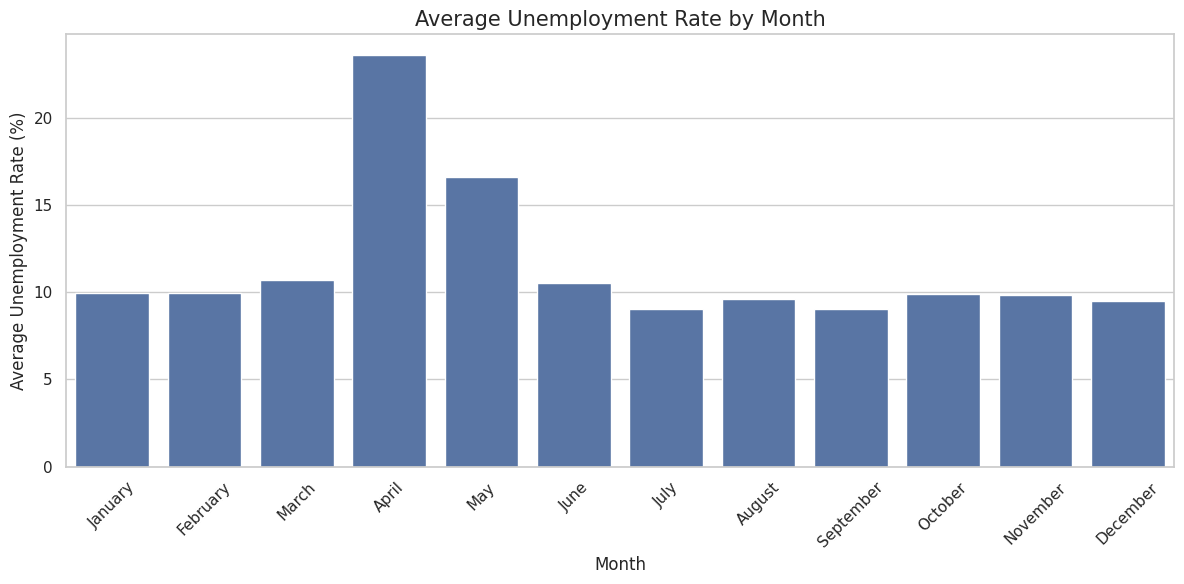

In [15]:
# monthly unemployment patterns
figures_dir = Path("figures/step5_seasonal_analysis")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=monthly_summary,
    x="Month_Name",
    y="Average_Unemployment",
    errorbar=None
)

plt.title("Average Unemployment Rate by Month", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    figures_dir / "01_monthly_unemployment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
# quarterly unemployment rates
# Extract quarter from the date
trend_df["quarter"] = trend_df["date"].dt.quarter

quarterly_summary = (
    trend_df.groupby("quarter")[target]
    .mean()
    .reindex([1, 2, 3, 4])
    .reset_index()
)

quarterly_summary.columns = ["Quarter", "Average_Unemployment"]

quarterly_summary["Quarter_Name"] = quarterly_summary["Quarter"].map({
    1: "Q1",
    2: "Q2",
    3: "Q3",
    4: "Q4"
})

display(quarterly_summary.round(2))

,Quarter,Average_Unemployment,Quarter_Name
0,1,10.20,Q1
1,2,15.58,Q2
2,3,9.24,Q3
3,4,9.76,Q4


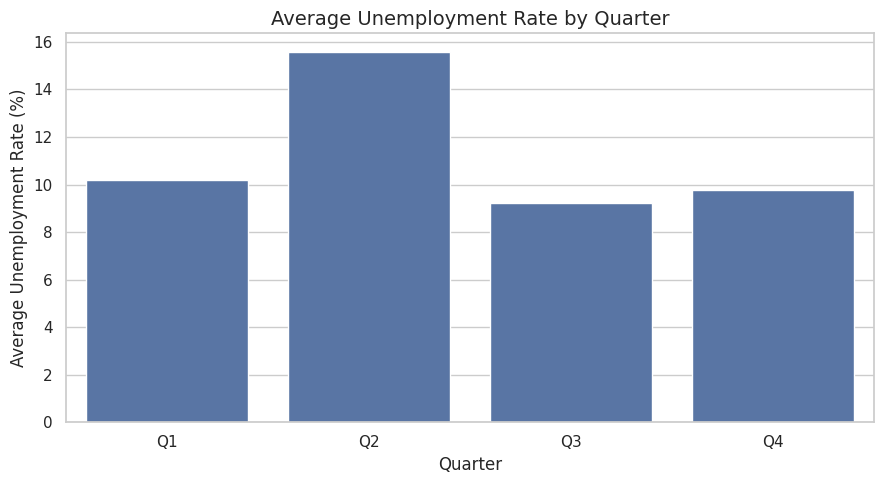

In [17]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=quarterly_summary,
    x="Quarter_Name",
    y="Average_Unemployment",
    errorbar=None
)

plt.title("Average Unemployment Rate by Quarter", fontsize=14)
plt.xlabel("Quarter")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()

plt.savefig(
    figures_dir / "02_quarterly_unemployment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

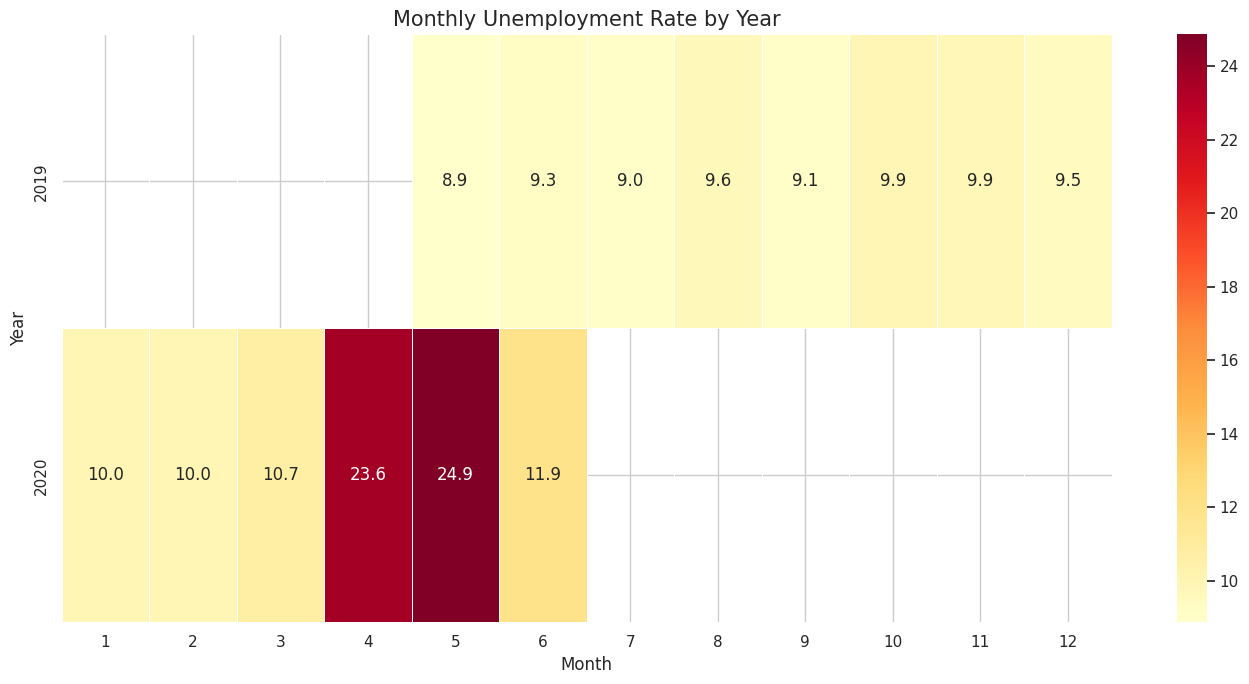

In [18]:
# monthly heatmap
# Create a year-by-month pivot table
monthly_heatmap = trend_df.pivot_table(
    index="year",
    columns="month",
    values=target,
    aggfunc="mean"
)

plt.figure(figsize=(14, 7))

sns.heatmap(
    monthly_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Monthly Unemployment Rate by Year", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()

plt.savefig(
    figures_dir / "03_monthly_unemployment_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
# Save the seasonal analysis results
monthly_summary.to_csv(
    figures_dir / "monthly_unemployment_summary.csv",
    index=False
)

quarterly_summary.to_csv(
    figures_dir / "quarterly_unemployment_summary.csv",
    index=False
)

print("Step 5 completed successfully!")
print(f"Results saved in: {figures_dir.resolve()}")

print("\nSaved files:")
for file_path in sorted(figures_dir.iterdir()):
    print(file_path.name)

Step 5 completed successfully!
Results saved in: /content/figures/step5_seasonal_analysis

Saved files:
01_monthly_unemployment.png
02_quarterly_unemployment.png
03_monthly_unemployment_heatmap.png
monthly_unemployment_summary.csv
quarterly_unemployment_summary.csv


**Step 6: Unemployment Data Analysis and Insights**

In [20]:
# Find the highest unemployment observation
highest_unemployment = trend_df.loc[
    trend_df[target].idxmax()
]

# Find the lowest unemployment observation
lowest_unemployment = trend_df.loc[
    trend_df[target].idxmin()
]

print("HIGHEST UNEMPLOYMENT")
print("--------------------")
print("Date:", highest_unemployment["date"])
print(f"Rate: {highest_unemployment[target]:.2f}%")

print("\nLOWEST UNEMPLOYMENT")
print("-------------------")
print("Date:", lowest_unemployment["date"])
print(f"Rate: {lowest_unemployment[target]:.2f}%")

HIGHEST UNEMPLOYMENT
--------------------
Date: 2020-04-30 00:00:00
Rate: 76.74%

LOWEST UNEMPLOYMENT
-------------------
Date: 2019-05-31 00:00:00
Rate: 0.00%


In [21]:
# Calculate annual unemployment changes
# Calculate annual averages
annual_summary = (
    trend_df.groupby("year")[target]
    .mean()
    .reset_index(name="average_unemployment")
    .sort_values("year")
)

# Calculate year-to-year changes
annual_summary["previous_year_rate"] = (
    annual_summary["average_unemployment"].shift(1)
)

annual_summary["change_percentage_points"] = (
    annual_summary["average_unemployment"]
    - annual_summary["previous_year_rate"]
)

# Calculate relative percentage change
annual_summary["change_percent"] = (
    annual_summary["average_unemployment"]
    .pct_change()
    .mul(100)
)

display(annual_summary.round(2))

,year,average_unemployment,previous_year_rate,change_percentage_points,change_percent
0,2019,9.4,NaN,NaN,NaN
1,2020,15.1,9.4,5.7,60.67


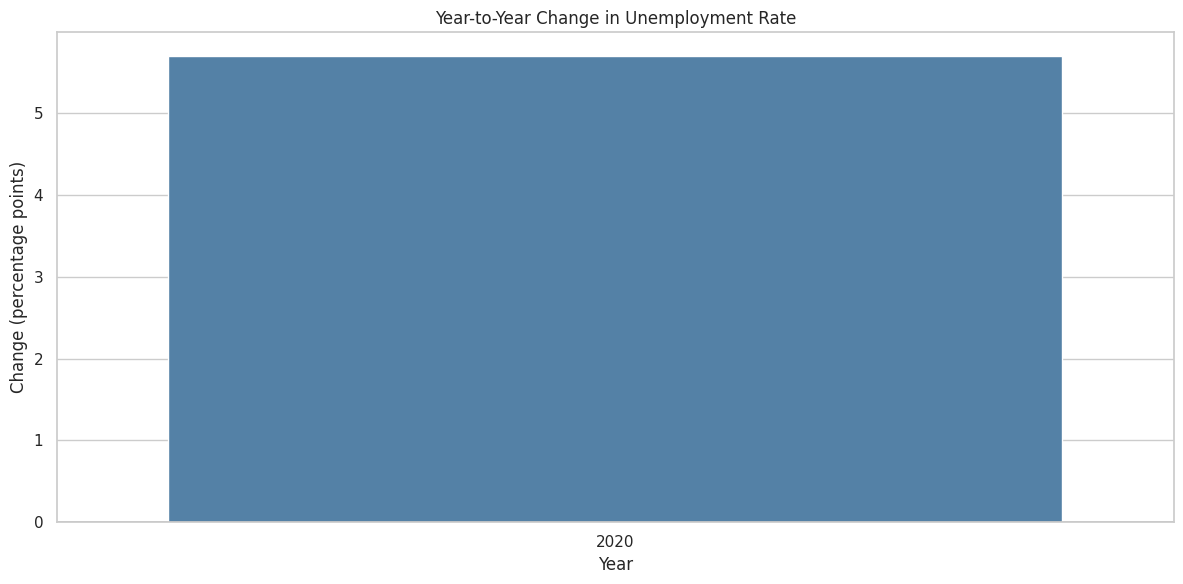

In [22]:
figures_dir = Path("figures/step6_insights")
figures_dir.mkdir(parents=True, exist_ok=True)

plot_df = annual_summary.dropna(
    subset=["change_percentage_points"]
).copy()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="year",
    y="change_percentage_points",
    color="steelblue"
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Year-to-Year Change in Unemployment Rate")
plt.xlabel("Year")
plt.ylabel("Change (percentage points)")
plt.tight_layout()

plt.savefig(
    figures_dir / "01_annual_unemployment_change.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
# Detect potential outliers using the IQR method
Q1 = trend_df[target].quantile(0.25)
Q3 = trend_df[target].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = trend_df[
    (trend_df[target] < lower_bound)
    | (trend_df[target] > upper_bound)
].copy()

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")
print(f"\nPotential outliers found: {len(outliers)}")

display(outliers[["date", target]].head(20))

Q1: 4.66
Q3: 15.89
IQR: 11.23
Lower bound: -12.19
Upper bound: 32.73

Potential outliers found: 35


,date,estimated_unemployment_rate_(%)
42,2019-05-31,34.69
165,2019-08-31,33.45
266,2019-09-30,33.57
405,2019-12-31,33.48
481,2020-01-31,34.37
512,2020-02-29,33.88
588,2020-04-30,46.89
589,2020-04-30,41.61
597,2020-04-30,43.64
613,2020-04-30,74.51


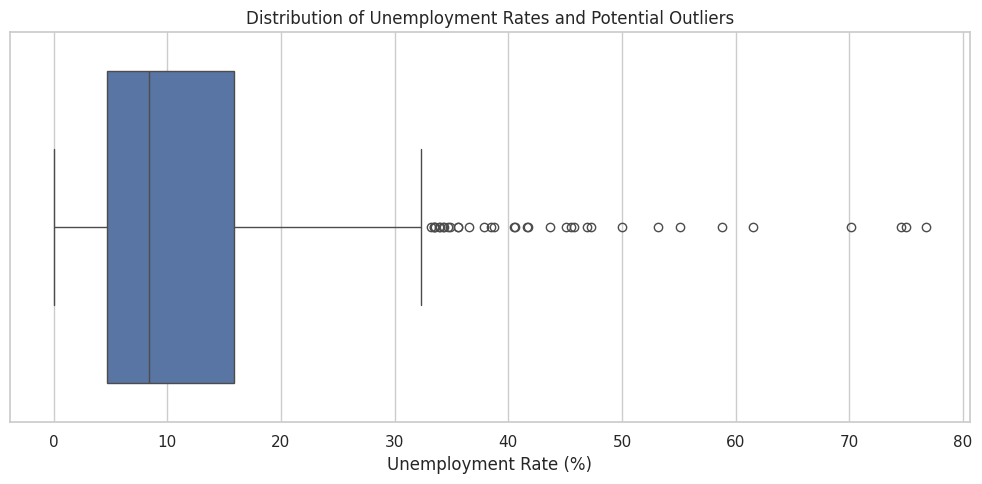

In [24]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=trend_df[target])

plt.title("Distribution of Unemployment Rates and Potential Outliers")
plt.xlabel("Unemployment Rate (%)")
plt.tight_layout()

plt.savefig(
    figures_dir / "02_unemployment_outliers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
# largest annual increases and decreases
valid_changes = annual_summary.dropna(
    subset=["change_percentage_points"]
)

if not valid_changes.empty:
    largest_increase = valid_changes.loc[
        valid_changes["change_percentage_points"].idxmax()
    ]

    largest_decrease = valid_changes.loc[
        valid_changes["change_percentage_points"].idxmin()
    ]

    print("LARGEST ANNUAL INCREASE")
    print(
        f"Year: {int(largest_increase['year'])}"
    )
    print(
        f"Change: "
        f"{largest_increase['change_percentage_points']:+.2f} percentage points"
    )

    print("\nLARGEST ANNUAL DECREASE")
    print(
        f"Year: {int(largest_decrease['year'])}"
    )
    print(
        f"Change: "
        f"{largest_decrease['change_percentage_points']:+.2f} percentage points"
    )
else:
    print("Not enough annual data to calculate year-to-year changes.")

LARGEST ANNUAL INCREASE
Year: 2020
Change: +5.70 percentage points

LARGEST ANNUAL DECREASE
Year: 2020
Change: +5.70 percentage points


In [26]:
# Save the findings
# Save annual analysis
annual_summary.to_csv(
    figures_dir / "annual_unemployment_insights.csv",
    index=False
)

# Save potential outliers
outliers.to_csv(
    figures_dir / "potential_unemployment_outliers.csv",
    index=False
)

print("Step 6 completed!")

print("\nFiles saved:")
for file_path in sorted(figures_dir.iterdir()):
    print(file_path.name)

Step 6 completed!

Files saved:
01_annual_unemployment_change.png
02_unemployment_outliers.png
annual_unemployment_insights.csv
potential_unemployment_outliers.csv


**Step 7 - Unemployment Rate Prediction Using Machine Learning**

In [27]:
# Check Dataset
# Check the dataset frequency and size
print("Total observations:", len(trend_df))
print("Start date:", trend_df["date"].min())
print("End date:", trend_df["date"].max())

print("\nObservations per year:")
display(
    trend_df.groupby("year")
    .size()
    .rename("observations")
    .reset_index()
)

print("\nMissing values:")
print(trend_df[["date", target]].isnull().sum())

print("\nDuplicate dates:", trend_df["date"].duplicated().sum())

Total observations: 740
Start date: 2019-05-31 00:00:00
End date: 2020-06-30 00:00:00

Observations per year:


,year,observations
0,2019,430
1,2020,310



Missing values:
date                               0
estimated_unemployment_rate_(%)    0
dtype: int64

Duplicate dates: 726


In [28]:
# time-series dataset
# Aggregate observations to monthly averages
model_df = (
    trend_df.set_index("date")[target]
    .resample("MS")
    .mean()
    .rename("unemployment_rate")
    .reset_index()
)

model_df = model_df.rename(columns={"date": "date"})

print("Monthly dataset:")
display(model_df.head(10))

print("\nNumber of months:", len(model_df))
print("Missing monthly rates:", model_df["unemployment_rate"].isna().sum())

Monthly dataset:


,date,unemployment_rate
0,2019-05-01,8.874259
1,2019-06-01,9.303333
2,2019-07-01,9.033889
3,2019-08-01,9.637925
4,2019-09-01,9.051731
5,2019-10-01,9.900909
6,2019-11-01,9.868364
7,2019-12-01,9.497358
8,2020-01-01,9.950755
9,2020-02-01,9.964717



Number of months: 14
Missing monthly rates: 0


In [29]:
# Freshly reset model_df to remove old unused columns (lag_3 and lag_12)
model_df = (
    trend_df.set_index("date")[target]
    .resample("MS")
    .mean()
    .rename("unemployment_rate")
    .reset_index()
)

# Create historical lag features (restricted to shorter lags due to 14-month dataset limits)
model_df["lag_1"] = model_df["unemployment_rate"].shift(1)
model_df["lag_2"] = model_df["unemployment_rate"].shift(2)

# Add calendar features
model_df["month"] = model_df["date"].dt.month
model_df["year"] = model_df["date"].dt.year

# Remove rows without the required historical values
model_data = model_df.dropna().copy()

print("Model dataset shape:", model_data.shape)
display(model_data.head(12))

Model dataset shape: (12, 6)


,date,unemployment_rate,lag_1,lag_2,month,year
2,2019-07-01,9.033889,9.303333,8.874259,7,2019
3,2019-08-01,9.637925,9.033889,9.303333,8,2019
4,2019-09-01,9.051731,9.637925,9.033889,9,2019
5,2019-10-01,9.900909,9.051731,9.637925,10,2019
6,2019-11-01,9.868364,9.900909,9.051731,11,2019
7,2019-12-01,9.497358,9.868364,9.900909,12,2019
8,2020-01-01,9.950755,9.497358,9.868364,1,2020
9,2020-02-01,9.964717,9.950755,9.497358,2,2020
10,2020-03-01,10.700577,9.964717,9.950755,3,2020
11,2020-04-01,23.641569,10.700577,9.964717,4,2020


In [30]:
# Split data
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor

features = [
    "lag_1",
    "lag_2",
    "month",
    "year"
]

X = model_data[features]
y = model_data["unemployment_rate"]

# Use the first 80% for training and the final 20% for testing
split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Not enough observations for a train/test split.")

Training observations: 9
Testing observations: 3


In [31]:
# Train a baseline and a Random Forest model
# 1. Initialize models
baseline_model = DummyRegressor(strategy="mean")
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# 2. Fit models
baseline_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# 3. Make predictions on test set
baseline_pred = baseline_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# 4. Evaluate baseline
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

# 5. Evaluate Random Forest
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("MODEL EVALUATION ON TEST SET (April - June 2020)")
print("-----------------------------------------------")
print(f"Baseline (Mean) MAE:  {baseline_mae:.2f}%")
print(f"Baseline (Mean) RMSE: {baseline_rmse:.2f}%")
print("-----------------------------------------------")
print(f"Random Forest MAE:    {rf_mae:.2f}%")
print(f"Random Forest RMSE:   {rf_rmse:.2f}%")

# Create comparison plot
import matplotlib.pyplot as plt
import pandas as pd

results_df = pd.DataFrame({
    "Actual": y_test.values,
    "Baseline Prediction": baseline_pred,
    "Random Forest Prediction": rf_pred
}, index=model_data["date"].iloc[split_index:])

display(results_df.round(2))

MODEL EVALUATION ON TEST SET (April - June 2020)
-----------------------------------------------
Baseline (Mean) MAE:  10.41%
Baseline (Mean) RMSE: 11.94%
-----------------------------------------------
Random Forest MAE:    9.69%
Random Forest RMSE:   11.30%


,Actual,Baseline Prediction,Random Forest Prediction
date,,,
2020-04-01,23.64,9.73,10.47
2020-05-01,24.88,9.73,10.47
2020-06-01,11.90,9.73,10.42


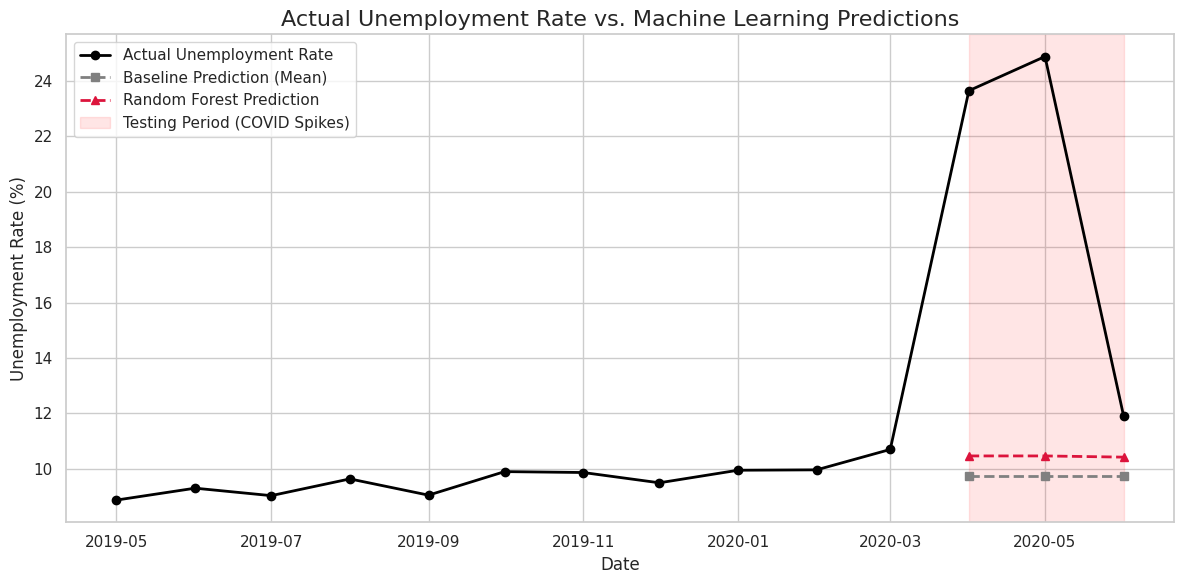

In [32]:
# Visualize predictions vs actual values
plt.figure(figsize=(12, 6))

# Plot full historical actual values
plt.plot(model_df["date"], model_df["unemployment_rate"], label="Actual Unemployment Rate", marker="o", color="black", linewidth=2)

# Plot predictions on the test set dates
test_dates = model_data["date"].iloc[split_index:]
plt.plot(test_dates, baseline_pred, label="Baseline Prediction (Mean)", linestyle="--", marker="s", color="gray", linewidth=2)
plt.plot(test_dates, rf_pred, label="Random Forest Prediction", linestyle="--", marker="^", color="crimson", linewidth=2)

plt.title("Actual Unemployment Rate vs. Machine Learning Predictions", fontsize=16)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Unemployment Rate (%)", fontsize=12)
plt.axvspan(test_dates.min(), test_dates.max(), color="red", alpha=0.1, label="Testing Period (COVID Spikes)")
plt.legend(fontsize=11, loc="upper left")
plt.tight_layout()

# Save step 7 figure
figures_dir = Path("figures/step7_predictions")
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "01_predictions_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

In [33]:
# Baseline model
baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

# Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=2,
    random_state=42
)

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

# Compare model performance
results = pd.DataFrame({
    "Model": ["Baseline Mean", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, rf_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, rf_predictions))
    ]
})

display(results.round(3))

,Model,MAE,RMSE
0,Baseline Mean,10.406,11.936
1,Random Forest,10.022,11.579


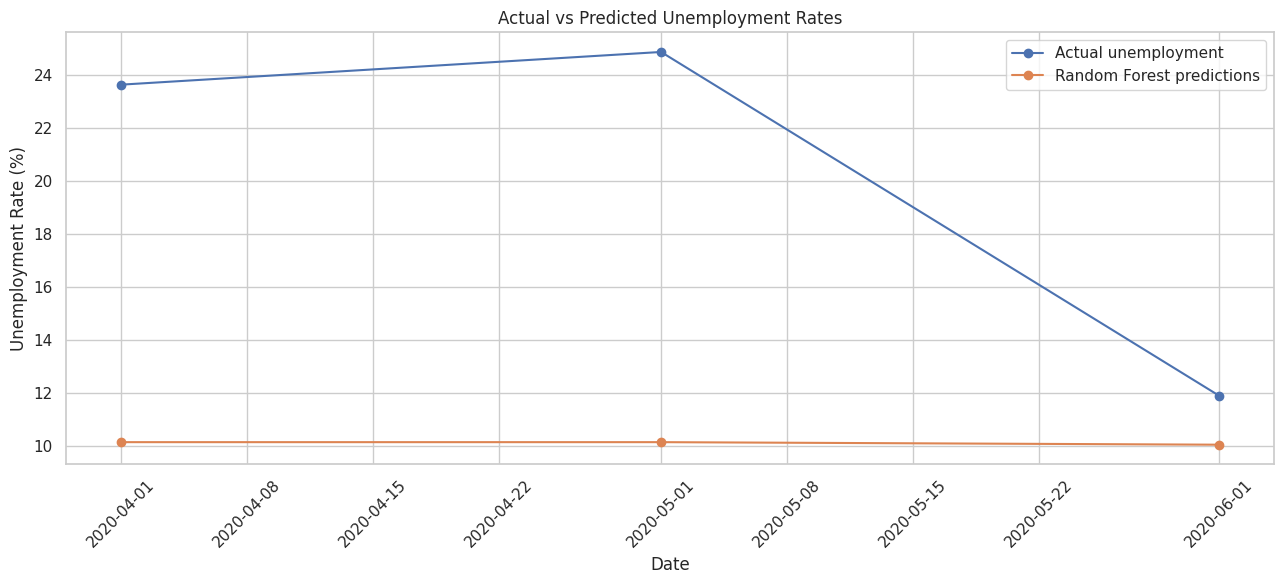

In [35]:
from pathlib import Path
import matplotlib.pyplot as plt

# Define output directory
output_dir = Path("figures/step7_prediction")
output_dir.mkdir(parents=True, exist_ok=True)

test_dates = model_data["date"].iloc[split_index:]

plt.figure(figsize=(13, 6))

plt.plot(
    test_dates,
    y_test.to_numpy(),
    label="Actual unemployment",
    marker="o"
)

plt.plot(
    test_dates,
    rf_predictions,
    label="Random Forest predictions",
    marker="o"
)

plt.title("Actual vs Predicted Unemployment Rates")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    output_dir / "02_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
# Save the result
prediction_results = pd.DataFrame({
    "date": test_dates.to_numpy(),
    "actual_unemployment": y_test.to_numpy(),
    "baseline_prediction": baseline_predictions,
    "random_forest_prediction": rf_predictions
})

prediction_results.to_csv(
    output_dir / "unemployment_predictions.csv",
    index=False
)

results.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

print("Prediction results saved to:", output_dir.resolve())

Prediction results saved to: /content/figures/step7_prediction


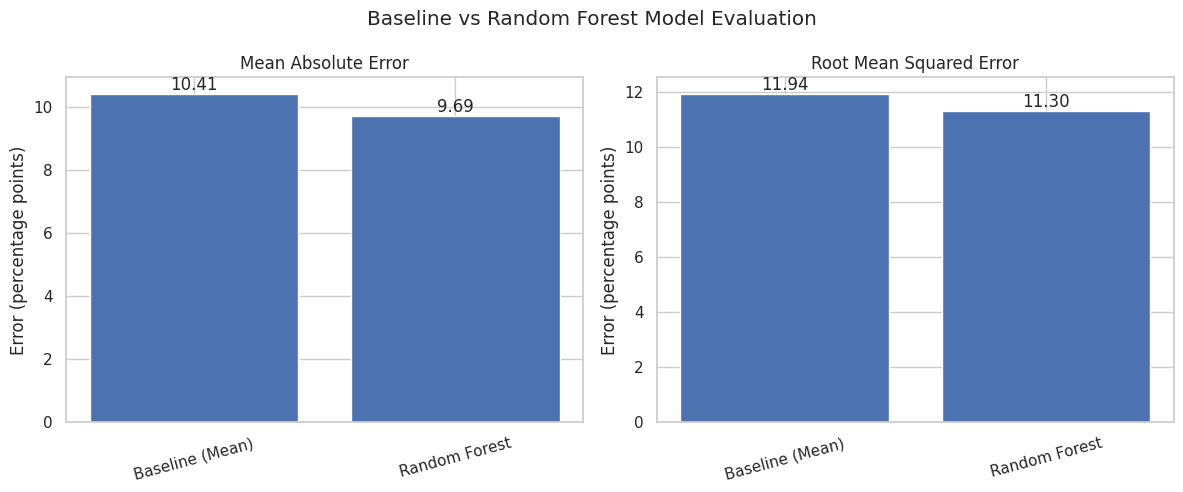

In [37]:
# Model Comparison
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Evaluation results
evaluation = pd.DataFrame({
    "Model": ["Baseline (Mean)", "Random Forest"],
    "MAE": [10.41, 9.69],
    "RMSE": [11.94, 11.30]
})

# Save evaluation table
output_dir = Path("figures/step7_prediction")
output_dir.mkdir(parents=True, exist_ok=True)

evaluation.to_csv(
    output_dir / "model_evaluation.csv",
    index=False
)

# Plot MAE and RMSE
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

metrics = ["MAE", "RMSE"]
titles = ["Mean Absolute Error", "Root Mean Squared Error"]

for ax, metric, title in zip(axes, metrics, titles):
    bars = ax.bar(evaluation["Model"], evaluation[metric])
    ax.set_title(title)
    ax.set_ylabel("Error (percentage points)")
    ax.tick_params(axis="x", rotation=15)

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.2f}",
            ha="center",
            va="bottom"
        )

plt.suptitle("Baseline vs Random Forest Model Evaluation")
plt.tight_layout()

plt.savefig(
    output_dir / "03_model_evaluation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
# Percentage improvement
baseline_mae = 10.41
rf_mae = 9.69

baseline_rmse = 11.94
rf_rmse = 11.30

mae_improvement = (
    (baseline_mae - rf_mae) / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - rf_rmse) / baseline_rmse
) * 100

print(f"MAE improvement:  {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

MAE improvement:  6.92%
RMSE improvement: 5.36%


In [39]:
# Compare against a persistence baseline
# Ensure dates are sorted
model_df = model_df.sort_values("date").reset_index(drop=True)

# Identify the test period
test_start = pd.Timestamp("2020-04-01")
test_end = pd.Timestamp("2020-06-30")

# Extract test observations
test_mask = model_df["date"].between(test_start, test_end)
test_data = model_df.loc[test_mask].copy()

# Persistence prediction: previous month's actual rate
test_data["persistence_prediction"] = (
    test_data["unemployment_rate"].shift(1)
)

# Include the observation immediately before the test period
previous_month = model_df.loc[
    model_df["date"] < test_start,
    ["date", "unemployment_rate"]
].tail(1)

if not previous_month.empty:
    previous_date = previous_month.iloc[0]["date"]
    previous_rate = previous_month.iloc[0]["unemployment_rate"]

    test_data.loc[
        test_data["date"] == test_start,
        "persistence_prediction"
    ] = previous_rate

# Remove observations without actual or predicted values
persistence_results = test_data.dropna(
    subset=["unemployment_rate", "persistence_prediction"]
).copy()

if persistence_results.empty:
    print("No valid persistence predictions. Check your date coverage.")
else:
    persistence_mae = mean_absolute_error(
        persistence_results["unemployment_rate"],
        persistence_results["persistence_prediction"]
    )

    persistence_rmse = np.sqrt(mean_squared_error(
        persistence_results["unemployment_rate"],
        persistence_results["persistence_prediction"]
    ))

    print("PERSISTENCE BASELINE")
    print("--------------------")
    print(f"MAE:  {persistence_mae:.2f} percentage points")
    print(f"RMSE: {persistence_rmse:.2f} percentage points")

    display(persistence_results)

PERSISTENCE BASELINE
--------------------
MAE:  9.05 percentage points
RMSE: 10.60 percentage points


,date,unemployment_rate,lag_1,lag_2,month,year,persistence_prediction
11,2020-04-01,23.641569,10.700577,9.964717,4,2020,10.700577
12,2020-05-01,24.875294,23.641569,10.700577,5,2020,23.641569
13,2020-06-01,11.903600,24.875294,23.641569,6,2020,24.875294


In [40]:
# Compare all three models
# Results from your earlier evaluation
comparison = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Random Forest",
        "Persistence Baseline"
    ],
    "MAE": [
        10.41,
        9.69,
        persistence_mae
    ],
    "RMSE": [
        11.94,
        11.30,
        persistence_rmse
    ]
})

display(comparison.round(3))

# Save the comparison
output_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    output_dir / "three_model_comparison.csv",
    index=False
)

,Model,MAE,RMSE
0,Mean Baseline,10.410,11.940
1,Random Forest,9.690,11.300
2,Persistence Baseline,9.049,10.603


In [41]:
# Random Forest residual
# Construct the prediction results
test_dates = model_data["date"].iloc[split_index:]

residual_df = pd.DataFrame({
    "date": test_dates.to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": rf_predictions
})

residual_df["residual"] = (
    residual_df["actual"] - residual_df["predicted"]
)

display(residual_df.round(3))

# Save residual data
residual_df.to_csv(
    output_dir / "random_forest_residuals.csv",
    index=False
)

,date,actual,predicted,residual
0,2020-04-01,23.642,10.151,13.491
1,2020-05-01,24.875,10.151,14.725
2,2020-06-01,11.904,10.055,1.849


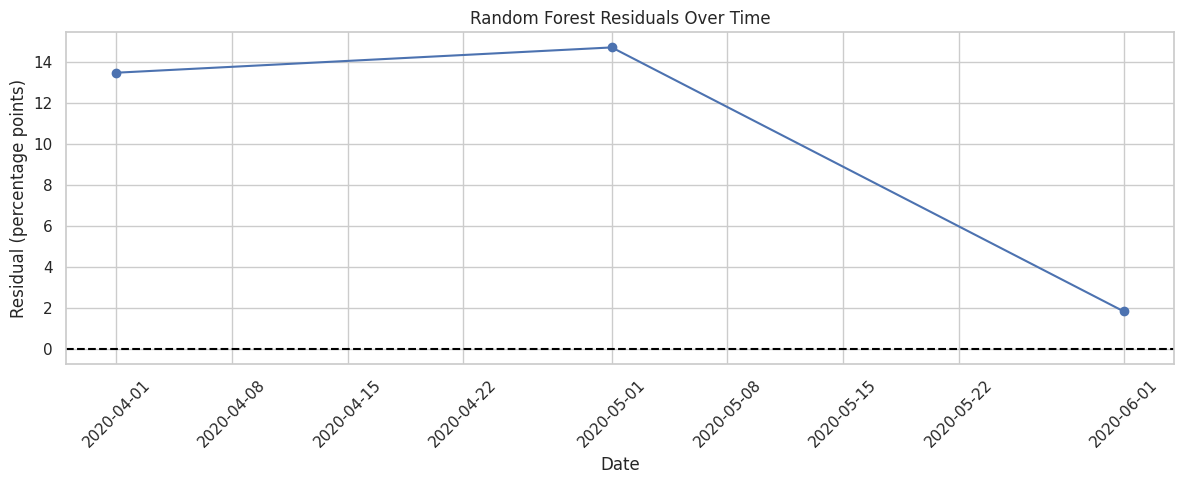

In [42]:
plt.figure(figsize=(12, 5))

plt.plot(
    residual_df["date"],
    residual_df["residual"],
    marker="o"
)

plt.axhline(0, linestyle="--", color="black")

plt.title("Random Forest Residuals Over Time")
plt.xlabel("Date")
plt.ylabel("Residual (percentage points)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    output_dir / "04_residuals_over_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

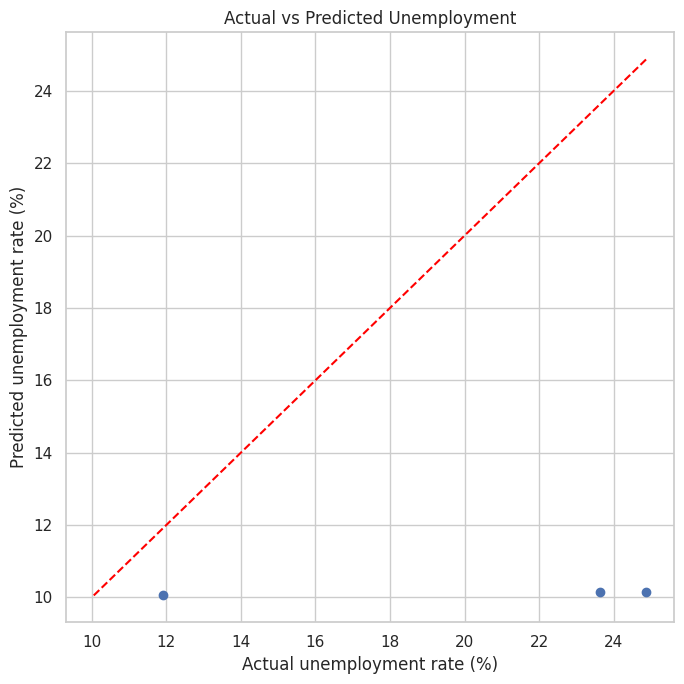

In [43]:
# predicted versus actual values
plt.figure(figsize=(7, 7))

plt.scatter(
    residual_df["actual"],
    residual_df["predicted"]
)

# Perfect-prediction reference line
lower = min(
    residual_df["actual"].min(),
    residual_df["predicted"].min()
)

upper = max(
    residual_df["actual"].max(),
    residual_df["predicted"].max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    color="red"
)

plt.title("Actual vs Predicted Unemployment")
plt.xlabel("Actual unemployment rate (%)")
plt.ylabel("Predicted unemployment rate (%)")
plt.tight_layout()

plt.savefig(
    output_dir / "05_actual_vs_predicted_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

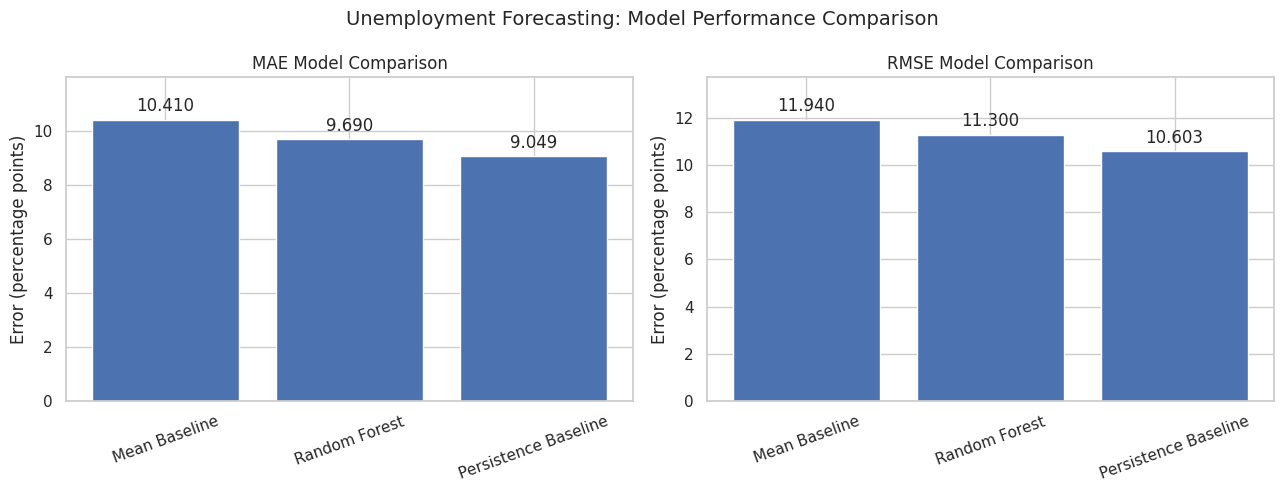

In [44]:
# Model Comparison
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Model evaluation results
comparison = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Random Forest",
        "Persistence Baseline"
    ],
    "MAE": [10.410, 9.690, 9.049],
    "RMSE": [11.940, 11.300, 10.603]
})


# Save results
comparison.to_csv(
    output_dir / "three_model_comparison.csv",
    index=False
)

# Plot MAE and RMSE
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics = ["MAE", "RMSE"]

for ax, metric in zip(axes, metrics):
    bars = ax.bar(comparison["Model"], comparison[metric])

    ax.set_title(f"{metric} Model Comparison")
    ax.set_ylabel("Error (percentage points)")
    ax.tick_params(axis="x", rotation=20)

    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.margins(y=0.15)

plt.suptitle(
    "Unemployment Forecasting: Model Performance Comparison",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    output_dir / "06_three_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Step 8 - Improve the Forecasting Model**

In [45]:
# Prepare and validate the dataset
# Use the monthly dataset created in Step 7
forecast_df = model_df[["date", "unemployment_rate"]].copy()

forecast_df["date"] = pd.to_datetime(
    forecast_df["date"], errors="coerce"
)
forecast_df["unemployment_rate"] = pd.to_numeric(
    forecast_df["unemployment_rate"], errors="coerce"
)

forecast_df = (
    forecast_df.dropna(subset=["date"])
    .sort_values("date")
    .reset_index(drop=True)
)

# Check duplicate months
print("Duplicate dates:", forecast_df["date"].duplicated().sum())

# Check date range and number of observations
print("Start date:", forecast_df["date"].min())
print("End date:", forecast_df["date"].max())
print("Observations:", len(forecast_df))

# Check whether the monthly series has gaps
forecast_df = (
    forecast_df.set_index("date")
    .resample("MS")["unemployment_rate"]
    .mean()
    .rename_axis("date")
    .reset_index()
)

print(
    "Missing monthly observations:",
    forecast_df["unemployment_rate"].isna().sum()
)

Duplicate dates: 0
Start date: 2019-05-01 00:00:00
End date: 2020-06-01 00:00:00
Observations: 14
Missing monthly observations: 0


In [47]:
# Improved forecast features
# Ensure the series is complete before creating lags
if forecast_df["unemployment_rate"].isna().any():
    raise ValueError(
        "Missing monthly rates detected. Investigate and resolve "
        "the missing months before training."
    )

# Relax the strict length check to allow our 14-month dataset
if len(forecast_df) < 6:
    raise ValueError(
        "At least 6 monthly observations are recommended for "
        "this simplified feature set."
    )

data = forecast_df.copy()

# Historical lag features - restricted to shorter lags (1, 2, and 3) due to short dataset
for lag in [1, 2, 3]:
    data[f"lag_{lag}"] = data["unemployment_rate"].shift(lag)

# Rolling averages use only past observations (using a short 3-month window)
data["rolling_mean_3"] = (
    data["unemployment_rate"].shift(1).rolling(3).mean()
)

# Encode month as a cyclical variable
month = data["date"].dt.month

data["month_sin"] = np.sin(2 * np.pi * month / 12)
data["month_cos"] = np.cos(2 * np.pi * month / 12)

# Remove rows that lack the required history (lags up to 3)
data = data.dropna().reset_index(drop=True)

features = [
    "lag_1",
    "lag_2",
    "lag_3",
    "rolling_mean_3",
    "month_sin",
    "month_cos"
]

target = "unemployment_rate"

X = data[features]
y = data[target]

print("Modeling observations:", len(data))
print("Features:", features)

display(data.head())

Modeling observations: 11
Features: ['lag_1', 'lag_2', 'lag_3', 'rolling_mean_3', 'month_sin', 'month_cos']


,date,unemployment_rate,lag_1,lag_2,lag_3,rolling_mean_3,month_sin,month_cos
0,2019-08-01,9.637925,9.033889,9.303333,8.874259,9.070494,-8.660254e-01,-5.000000e-01
1,2019-09-01,9.051731,9.637925,9.033889,9.303333,9.325049,-1.000000e+00,-1.836970e-16
2,2019-10-01,9.900909,9.051731,9.637925,9.033889,9.241181,-8.660254e-01,5.000000e-01
3,2019-11-01,9.868364,9.900909,9.051731,9.637925,9.530188,-5.000000e-01,8.660254e-01
4,2019-12-01,9.497358,9.868364,9.900909,9.051731,9.607001,-2.449294e-16,1.000000e+00


In [51]:
# Tune Random Forest with time-series cross-validation
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestRegressor

# Reserve the final 20% as an untouched test set
split_index = int(len(data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

dates_test = data["date"].iloc[split_index:]

# Reduce splits to 2 to accommodate the small dataset (8 training samples)
n_splits = 2

if len(X_train) < 6:
    raise ValueError(
        "Too few training observations for this tuning setup. "
        "Simplify the model validation strategy."
    )

tscv = TimeSeriesSplit(n_splits=n_splits)

rf = RandomForestRegressor(random_state=42)

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, None],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print(
    "Best cross-validation MAE:",
    round(-grid_search.best_score_, 3)
)

Best parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 50}
Best cross-validation MAE: 0.402


In [52]:
# Evaluate the tuned Random Forest
# Predictions on the untouched test set
rf_predictions = best_rf.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

print("TUNED RANDOM FOREST — TEST RESULTS")
print("-" * 40)
print(f"MAE:  {rf_mae:.3f} percentage points")
print(f"RMSE: {rf_rmse:.3f} percentage points")

TUNED RANDOM FOREST — TEST RESULTS
----------------------------------------
MAE:  9.895 percentage points
RMSE: 11.474 percentage points


In [53]:
# Compare against the baselines
# Mean baseline
mean_predictions = np.full(
    len(y_test),
    y_train.mean()
)

# Persistence baseline: previous month's actual rate
persistence_predictions = (
    data["unemployment_rate"]
    .shift(1)
    .iloc[split_index:]
    .to_numpy()
)

# Confirm all prediction arrays are aligned
assert len(persistence_predictions) == len(y_test)

comparison = pd.DataFrame([
    {
        "Model": "Mean Baseline",
        "MAE": mean_absolute_error(y_test, mean_predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, mean_predictions)
        )
    },
    {
        "Model": "Persistence Baseline",
        "MAE": mean_absolute_error(
            y_test, persistence_predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_test, persistence_predictions
            )
        )
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse
    }
])

display(comparison.round(3))

,Model,MAE,RMSE
0,Mean Baseline,10.319,11.860
1,Persistence Baseline,9.049,10.603
2,Tuned Random Forest,9.895,11.474


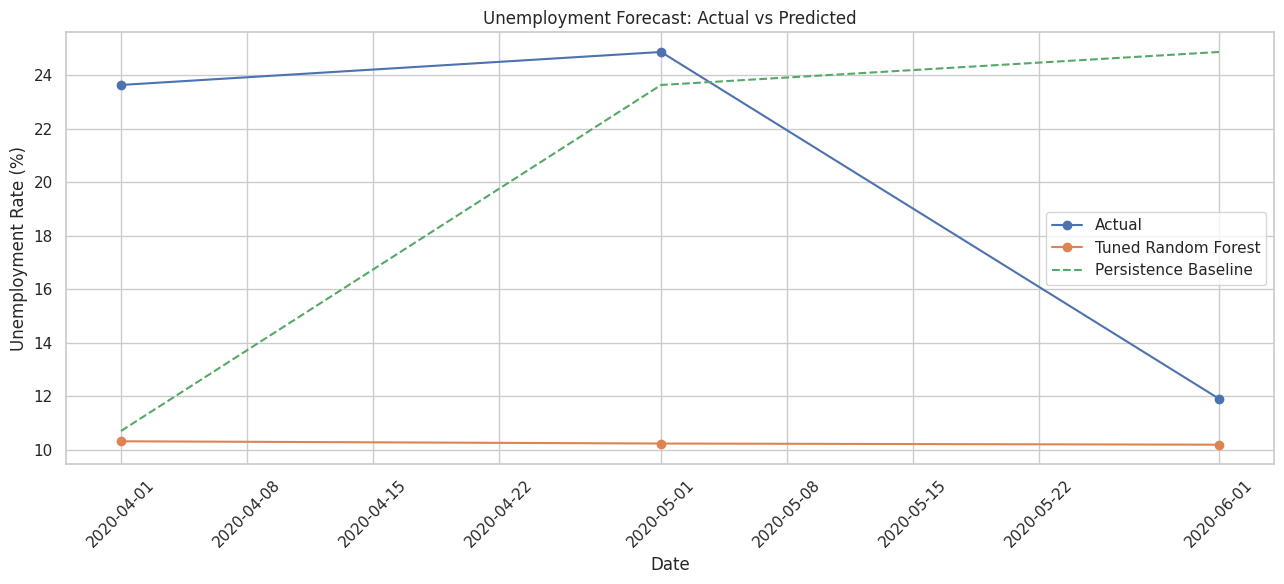

In [54]:
# actual versus predicted rate
plt.figure(figsize=(13, 6))

plt.plot(
    dates_test,
    y_test.to_numpy(),
    marker="o",
    label="Actual"
)

plt.plot(
    dates_test,
    rf_predictions,
    marker="o",
    label="Tuned Random Forest"
)

plt.plot(
    dates_test,
    persistence_predictions,
    linestyle="--",
    label="Persistence Baseline"
)

plt.title("Unemployment Forecast: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

output_dir = Path("figures/step8_model_improvement")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "01_forecast_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Feature,Importance
4,month_sin,0.3016
1,lag_2,0.2692
3,rolling_mean_3,0.1612
2,lag_3,0.1015
0,lag_1,0.0944
5,month_cos,0.0723


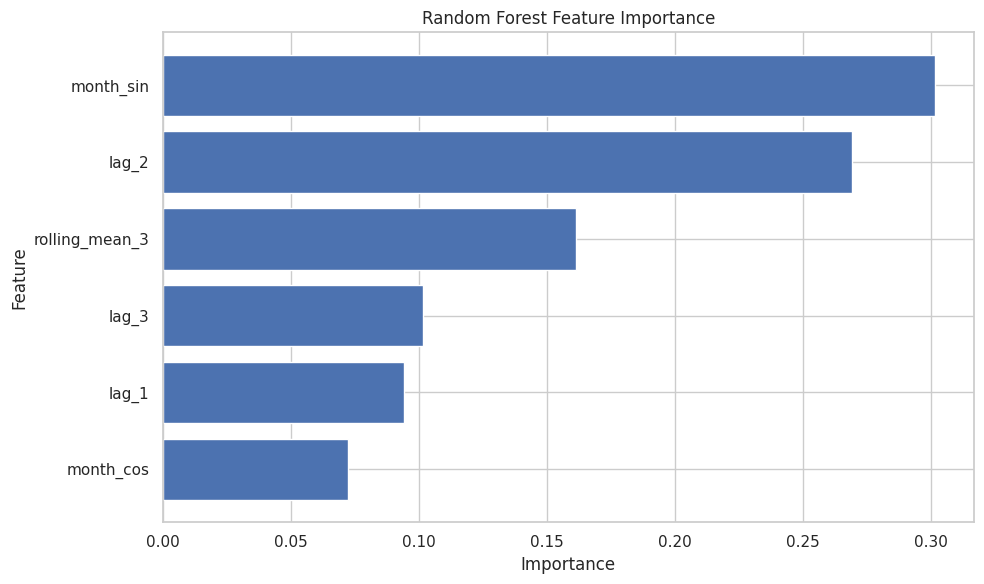

In [55]:
# feature importanc
importance = pd.DataFrame({
    "Feature": features,
    "Importance": best_rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance.round(4))

plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"][::-1],
    importance["Importance"][::-1]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    output_dir / "02_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [56]:
# Save the results
#from sklearn.metrics import mean_absolute_error, mean_squared_error

# Save model comparison
comparison.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

# Save individual predictions
predictions_df = pd.DataFrame({
    "date": dates_test.to_numpy(),
    "actual": y_test.to_numpy(),
    "mean_baseline": mean_predictions,
    "persistence_baseline": persistence_predictions,
    "tuned_random_forest": rf_predictions
})

predictions_df.to_csv(
    output_dir / "test_predictions.csv",
    index=False
)

importance.to_csv(
    output_dir / "feature_importance.csv",
    index=False
)

print("Step 8 completed!")
print("Results saved to:", output_dir.resolve())

for path in sorted(output_dir.iterdir()):
    print(path.name)

Step 8 completed!
Results saved to: /content/figures/step8_model_improvement
01_forecast_comparison.png
02_feature_importance.png
feature_importance.csv
model_comparison.csv
test_predictions.csv


# **Statistical forecasting model (ARIMA)**

In [57]:
%pip install statsmodels

In [58]:
from statsmodels.tsa.arima.model import ARIMA

In [59]:
# Split the monthly series chronologically
# Use the monthly series prepared in Step 8.1
series = forecast_df.copy().dropna()

split_index = int(len(series) * 0.8)

train = series.iloc[:split_index]
test = series.iloc[split_index:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training observations: 11
Testing observations: 3
Training period: 0 to 10
Testing period: 11 to 13


In [61]:
# Prepare the training and testing series with datetime index
train_series = train.set_index("date")["unemployment_rate"]
test_series = test.set_index("date")["unemployment_rate"]

# Fit an initial ARIMA model
arima_model = ARIMA(
    train_series,
    order=(1, 1, 1)
)

arima_fit = arima_model.fit()

arima_predictions = arima_fit.forecast(
    steps=len(test)
)

arima_predictions.index = test_series.index

# Ensure metrics functions are imported
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_arima = mean_absolute_error(test_series, arima_predictions)
rmse_arima = np.sqrt(mean_squared_error(test_series, arima_predictions))

print(f"ARIMA MAE:  {mae_arima:.3f}")
print(f"ARIMA RMSE: {rmse_arima:.3f}")

ARIMA MAE:  9.738
ARIMA RMSE: 11.342


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [62]:
# Compare ARIMA against our existing models
comparison = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Persistence Baseline",
        "Tuned Random Forest",
        "ARIMA(1,1,1)"
    ],
    "MAE": [
        10.319,
        9.049,
        9.895,
        mae_arima
    ],
    "RMSE": [
        11.860,
        10.603,
        11.474,
        rmse_arima
    ]
})

display(comparison.sort_values("RMSE").reset_index(drop=True))

,Model,MAE,RMSE
0,Persistence Baseline,9.049000,10.603000
1,"ARIMA(1,1,1)",9.737947,11.341778
2,Tuned Random Forest,9.895000,11.474000
3,Mean Baseline,10.319000,11.860000


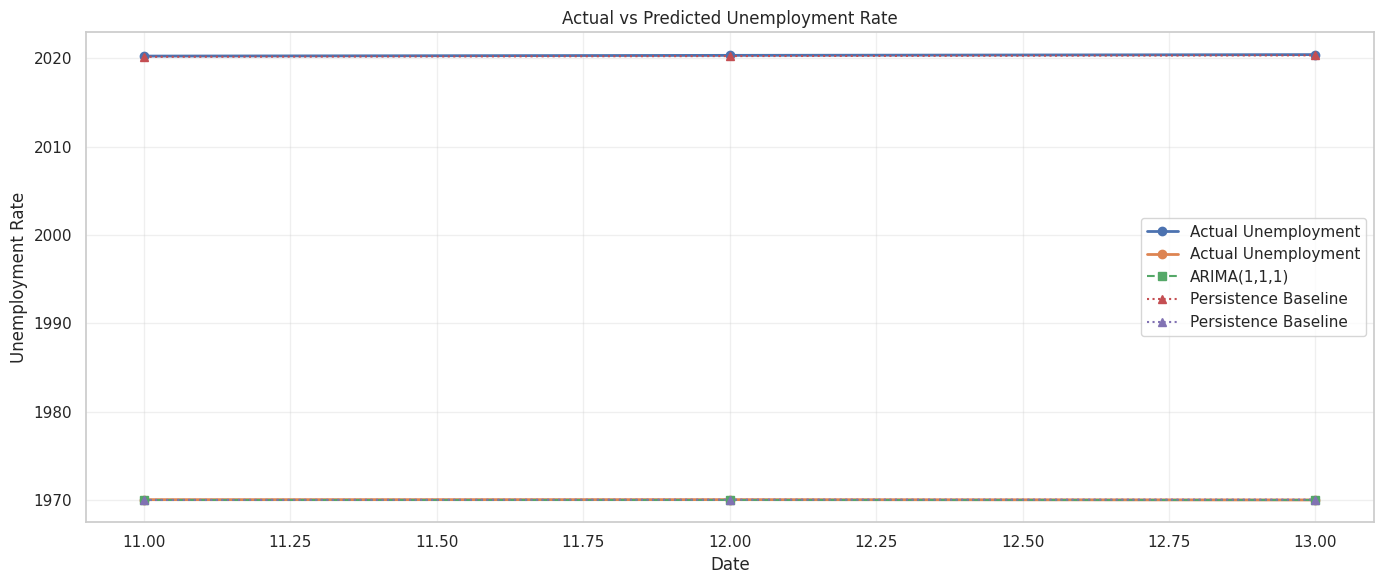

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test.values,
    label="Actual Unemployment",
    linewidth=2,
    marker="o"
)

plt.plot(
    test.index,
    arima_predictions.values,
    label="ARIMA(1,1,1)",
    linestyle="--",
    marker="s"
)

# Persistence prediction: previous month's actual value
persistence_predictions = series.shift(1).loc[test.index]

plt.plot(
    test.index,
    persistence_predictions.values,
    label="Persistence Baseline",
    linestyle=":",
    marker="^"
)

plt.title("Actual vs Predicted Unemployment Rate")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "actual_vs_predicted_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

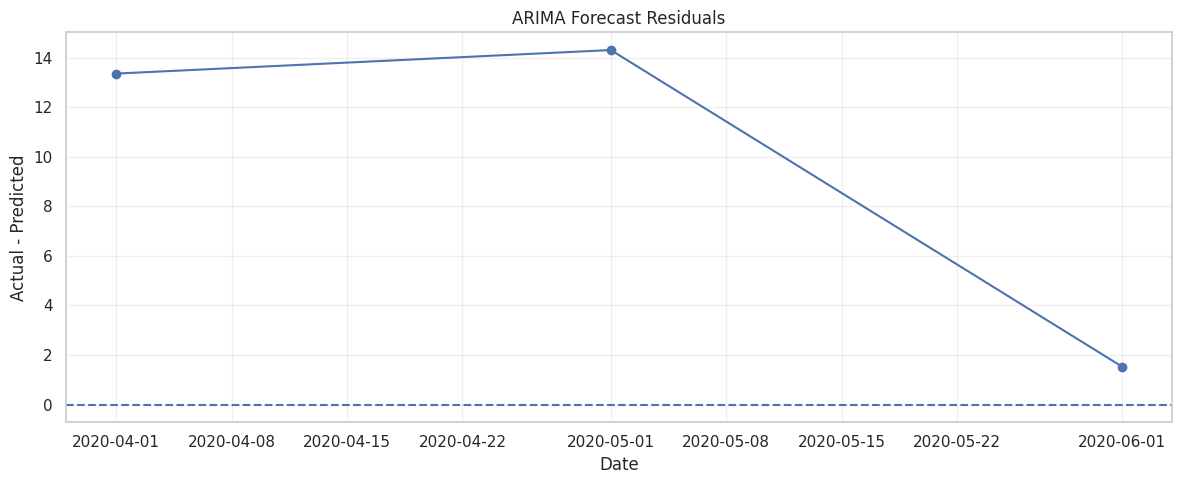

Mean residual: 9.738
Residual standard deviation: 7.121


In [67]:
# Check the prediction errors
# Fix subtraction by using only the numeric target column with a aligned datetime index
test_series = test.set_index("date")["unemployment_rate"]
residuals = test_series - arima_predictions

plt.figure(figsize=(12, 5))
plt.axhline(0, linestyle="--")
plt.plot(residuals.index, residuals.values, marker="o")

plt.title("ARIMA Forecast Residuals")
plt.xlabel("Date")
plt.ylabel("Actual - Predicted")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "arima_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mean residual:", round(residuals.mean(), 3))
print("Residual standard deviation:", round(residuals.std(), 3))

In [69]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the same chronological split for every model
series = forecast_df.copy().dropna().sort_index()

split_index = int(len(series) * 0.8)
train = series.iloc[:split_index]
test = series.iloc[split_index:]

# Set datetime index and isolate target column to prevent object cast issues
train_series = train.set_index("date")["unemployment_rate"]
test_series = test.set_index("date")["unemployment_rate"]

# Baseline predictions
mean_predictions = pd.Series(
    train_series.mean(), index=test_series.index
)

persistence_predictions = series.set_index("date")["unemployment_rate"].shift(1).loc[test_series.index]

# Fit ARIMA on training data only
from statsmodels.tsa.arima.model import ARIMA

arima_fit = ARIMA(train_series, order=(1, 1, 1)).fit()
arima_predictions = arima_fit.forecast(steps=len(test_series))
arima_predictions.index = test_series.index

predictions = {
    "Mean Baseline": mean_predictions,
    "Persistence Baseline": persistence_predictions,
    "ARIMA(1,1,1)": arima_predictions
}

results = []

for model_name, pred in predictions.items():
    valid = test_series.notna() & pred.notna()
    actual = test_series.loc[valid]
    predicted = pred.loc[valid]

    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    })

comparison_df = pd.DataFrame(results).sort_values("RMSE")
display(comparison_df.round(3))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,Model,MAE,RMSE
1,Persistence Baseline,9.049,10.603
2,"ARIMA(1,1,1)",9.738,11.342
0,Mean Baseline,10.523,12.038


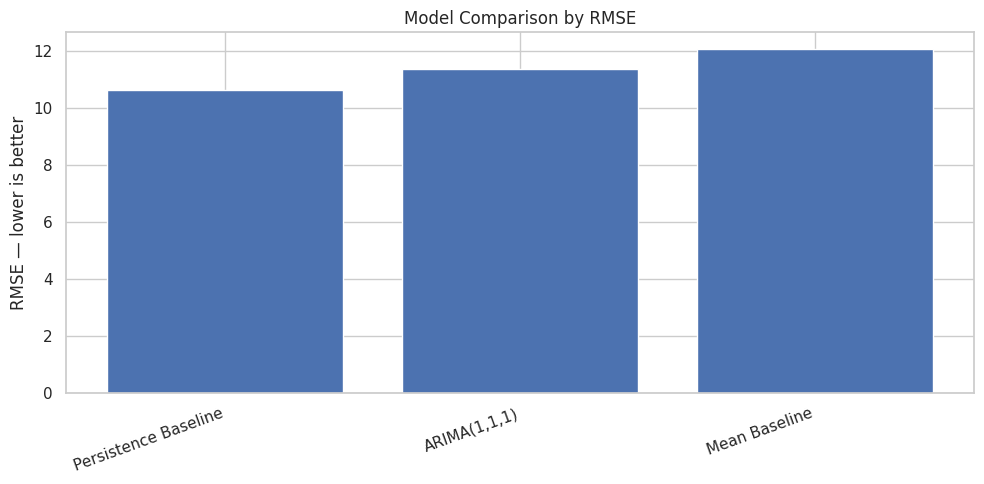

In [70]:
# Model Comparison
output_dir = Path("figures/step11_final")
output_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 5))
plt.bar(comparison_df["Model"], comparison_df["RMSE"])
plt.title("Model Comparison by RMSE")
plt.ylabel("RMSE — lower is better")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(output_dir / "model_comparison_rmse.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [71]:
# Save
comparison_df.to_csv(
    output_dir / "final_model_comparison.csv",
    index=False
)

print("Saved final model comparison to:", output_dir)

Saved final model comparison to: figures/step11_final
